Tutorial: prescribed displacement at the tip of a cantilever
===

A cantilever of 10 `BeamC` elements, clamped at $x = 0$, whose free end is
given the transverse deflection $\delta$ with no applied load. The prescribed
deflection is imposed by partitioning the degrees of freedom (dofs) into the
free ones, `bu`, and the known ones, `bk`, with the prescribed values `uk`,
see the user guide page *Linear static analyses*. The deflected shape and
the reactions, at the tip where the deflection is prescribed and at the
clamp, are compared with the closed form of the Timoshenko beam.

The problem is solved in two ways: by the partition written by hand with
SciPy, and with `Analysis(..., bu=bu, uk=uk)` in a single linear step.

Reference:

- Bathe, K. J., *Finite Element Procedures*, 2nd ed., K. J. Bathe,
  Watertown, MA, 2014: Sec. 4.2.2, Eqs. (4.42), (4.43) and (4.45), the
  partition of the prescribed displacements; Sec. 1.2, Eq. (1.2), the tip
  deflection of a cantilever with shear deformation.

The model and the checks are those of
`tests/test_prescribed_displacement_linear.py`, imported below.

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

from pyfe3d import DOF
from pyfe3d.solver import solve, Analysis
from test_prescribed_displacement_linear import (cantilever_prop, cantilever,
    boundary_conditions, timoshenko_cantilever, tip_force, internal_forces,
    check_reactions)
import test_prescribed_displacement_linear as tpd

Model
---

Rectangular aluminium cross section, width $b = 0.1$ m along $y$, height
$h = 0.2$ m along $z$, length $L = 1$ m ($L/h = 5$), $E = 70$ GPa,
$\nu = 0.3$, prescribed tip deflection $\delta = 10$ mm along $Z$.
`BeamProp` applies no shear correction factor, so the factor $k = 5/6$ of the
rectangle is put in the transverse shear modulus of the bending plane $xz$,
`prop.G13` $= k G$. `BeamC` uses it as $k G A$ = `G13*A`, in its shear
stiffness and in the shear parameter $\alpha_z = -12 E I_{yy}/(G_{13} A
L_e^2)$ of its shape functions, with $L_e$ the element length. The bending
stiffness of the deflection $w$ is $E I_{yy}$, with $I_{yy} = b h^3/12$.

In [2]:
prop, L, delta = cantilever_prop()
print('A = %g m2, Iyy = %g m4, E = %g Pa, G13 = k G = %g Pa'
      % (prop.A, prop.Iyy, prop.E, prop.G13))
nodes, ncoords, elements, KC0 = cantilever(prop, L, num_elements=10)
N = KC0.shape[0]
bk, bu, uk, tip_w = boundary_conditions(N, delta)
f = np.zeros(N) # no applied load
print('N = %d dofs, %d free, %d known; uk[tip_w] = %g m'
      % (N, bu.sum(), bk.sum(), uk[tip_w]))

A = 0.02 m2, Iyy = 6.66667e-05 m4, E = 7e+10 Pa, G13 = k G = 2.24359e+10 Pa
N = 66 dofs, 59 free, 7 known; uk[tip_w] = 0.01 m


Closed form
---

For a Timoshenko cantilever loaded by a tip force $P$, the bending moment is
$M(x) = P (L - x)$ and the shear force $Q = P$. With the rotation of the
cross section $\theta$, $E I \theta_{,x} = M$, and the shear strain is
$\gamma = w_{,x} - \theta = P/(k G A)$. Integrating with the clamp
conditions $w(0) = \theta(0) = 0$:

$$
\theta(x) = \frac{P}{E I}\left(L x - \frac{x^2}{2}\right), \qquad
w(x) = \frac{P}{E I}\left(\frac{L x^2}{2} - \frac{x^3}{6}\right)
     + \frac{P x}{k G A}
$$

At $x = L$, $w(L) = P \left(\frac{L^3}{3EI} + \frac{L}{kGA}\right)$, which is
Eq. (1.2) of Bathe (2014). Prescribing $w(L) = \delta$ gives the tip
reaction

$$
P = \frac{\delta}{\dfrac{L^3}{3 E I} + \dfrac{L}{k G A}}
\quad \xrightarrow{k G A \to \infty} \quad
P_{EB} = \frac{3 E I \delta}{L^3}
$$

the Euler-Bernoulli value. The clamp reactions balance it: the force
$-P$ along $Z$ and the moment $M_Y = P L$, from the moment equilibrium about
the clamp, $M_Y \boldsymbol{e}_Y + (L, 0, 0) \times (0, 0, P) = \boldsymbol{0}$. In
pyfe3d the rotation about $Y$ is $r_y = -\theta$, since the axial
displacement of a point at the height $z$ is $u + z r_y$ (*Conventions*,
sign conventions). The derivation is verified with SymPy by
`test_closed_form_timoshenko_cantilever` of the test file, run here:

In [3]:
tpd.test_closed_form_timoshenko_cantilever()
P, P_EB = tip_force(delta, prop, L)
print('Timoshenko      P    = %.6e N' % P)
print('Euler-Bernoulli P_EB = %.6e N, %.2f %% larger'
      % (P_EB, 100*(P_EB/P - 1)))
print('shear/bending flexibility 3EI/(L^2 kGA) = %.4f'
      % (3*prop.E*prop.Iyy/(L**2*prop.G13*prop.A)))

Timoshenko      P    = 1.357642e+05 N
Euler-Bernoulli P_EB = 1.400000e+05 N, 3.12 % larger
shear/bending flexibility 3EI/(L^2 kGA) = 0.0312


The shear flexibility of this beam is 3.1 % of its bending flexibility,
$3 E I/(L^2 k G A) = \frac{E}{4 k G}(h/L)^2$ for the rectangle: the
Euler-Bernoulli tip force is 3.1 % larger than the Timoshenko one, a
difference that is visible below but small.

1. Partition by hand with SciPy
---

The dofs need not be reordered: the Boolean arrays select the blocks. The
free dofs solve

$$
\boldsymbol{K}_{{C0}_{uu}} \boldsymbol{u}_u = \boldsymbol{f}_u - \boldsymbol{K}_{{C0}_{uk}} \boldsymbol{u}_k
$$

and the reactions follow from the second row of the partition,
$\boldsymbol{K}_{{C0}_{ku}} \boldsymbol{u}_u + \boldsymbol{K}_{{C0}_{kk}} \boldsymbol{u}_k - \boldsymbol{f}_k$,
equal to the internal forces of `update_fint` at the known dofs minus the
loads applied there, $\boldsymbol{F}_{{int}_k} - \boldsymbol{f}_k$. These are Eqs. (4.43)
and (4.45) of Bathe (2014), with the known set written $k$, as in pyfe3d.

In [4]:
KC0uu = KC0[bu, :][:, bu]
KC0uk = KC0[bu, :][:, bk]
KC0ku = KC0[bk, :][:, bu]
KC0kk = KC0[bk, :][:, bk]

u = np.zeros(N)
u[bk] = uk[bk]
u[bu] = solve(KC0uu, f[bu] - KC0uk @ uk[bk])

R_partition = KC0ku @ u[bu] + KC0kk @ uk[bk] - f[bk]
R = internal_forces(elements, prop, u, ncoords) - f
assert np.allclose(R[bk], R_partition, rtol=1e-12, atol=1e-12*P*L)

print('tip reaction  FE %.10e N, closed form %.10e N, rel. diff. %.1e'
      % (R[tip_w], P, abs(R[tip_w]/P - 1)))
print('clamp forces  [N]   ', R[0:3])
print('clamp moments [N m] ', R[3:6], ' P L =', P*L)
check_reactions(R, nodes, L, P, rtol=1e-9)

tip reaction  FE 1.3576415826e+05 N, closed form 1.3576415826e+05 N, rel. diff. 1.4e-14
clamp forces  [N]    [      0.               0.         -135764.15826221]
clamp moments [N m]  [     0.         135764.15826222      0.        ]  P L = 135764.1582622188


`check_reactions` asserts, with a relative tolerance of $10^{-9}$, the tip
reaction $P$, the clamp force $(0, 0, -P)$, the clamp moment $M_Y = P L$ with
the moment equilibrium of all the reactions about the origin, and zero
forces at the free dofs. `BeamC` solves the homogeneous equations of the
Timoshenko beam exactly, so the agreement is to round-off.

The deflected shape: the nodal deflections and rotations against the closed
form, with the tolerance $10^{-10} \delta$, and $w(x)$ plotted with the
Euler-Bernoulli shape of the same tip deflection,
$w_{EB}(x) = \delta \left(\frac{3 x^2}{2 L^2} - \frac{x^3}{2 L^3}\right)$.

max |w_FE - w| / delta          = 2.2e-15
max |r_y,FE + theta| / theta(L) = 7.4e-15


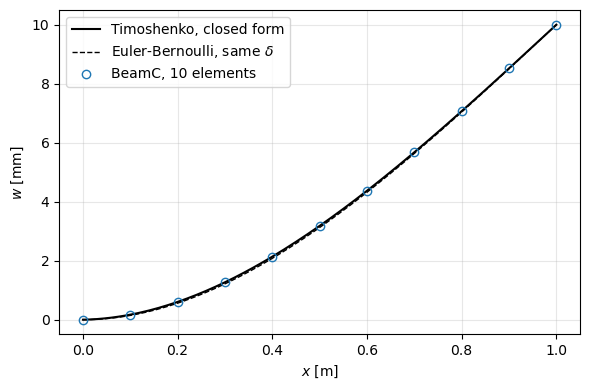

largest difference Timoshenko - Euler-Bernoulli: 0.058 mm at x = 0.42 m


In [5]:
w_ref, theta_ref = timoshenko_cantilever(nodes, P, prop, L)
w_fe = u[2::DOF]
ry_fe = u[4::DOF]
print('max |w_FE - w| / delta          = %.1e' % (abs(w_fe - w_ref).max()/delta))
print('max |r_y,FE + theta| / theta(L) = %.1e'
      % (abs(ry_fe + theta_ref).max()/theta_ref[-1]))
assert np.allclose(w_fe, w_ref, rtol=0, atol=1e-10*delta)
assert np.allclose(ry_fe, -theta_ref, rtol=0, atol=1e-10*theta_ref[-1])

xs = np.linspace(0, L, 201)
w_cf, _ = timoshenko_cantilever(xs, P, prop, L)
w_eb = delta*(3*xs**2/(2*L**2) - xs**3/(2*L**3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xs, 1e3*w_cf, 'k-', label='Timoshenko, closed form')
ax.plot(xs, 1e3*w_eb, 'k--', lw=1, label='Euler-Bernoulli, same $\\delta$')
ax.plot(nodes, 1e3*w_fe, 'o', mfc='none', label='BeamC, 10 elements')
ax.set_xlabel('$x$ [m]')
ax.set_ylabel('$w$ [mm]')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

i = np.argmax(abs(w_cf - w_eb))
print('largest difference Timoshenko - Euler-Bernoulli: %.3f mm at x = %.2f m'
      % (1e3*(w_cf - w_eb)[i], xs[i]))

2. `Analysis` with `bu` and `uk`
---

`Analysis` receives the callables of the full model and the partition: the
known dofs are those of `~bu`, with the prescribed values `uk[~bu]`, imposed
exactly. The linear analysis, `static(NLgeom=False)`, solves the same system
$\boldsymbol{K}_{{C0}_{uu}} \boldsymbol{u}_u = \boldsymbol{f}_u - \boldsymbol{K}_{{C0}_{uk}} \boldsymbol{u}_k$ in a
single step and returns `cs[0]` of size `N`, with the prescribed values at
the known dofs. `calc_fext` returns zeros: the analysis is displacement
controlled. The reactions are `calc_fint(u) - calc_fext()` at the known dofs.

In [6]:
def calc_fext(inc=1., silent=True):
    return np.zeros(N)

def calc_kC(c=None, NLgeom=False, silent=True):
    return KC0

def calc_fint(c, silent=True):
    return internal_forces(elements, prop, c, ncoords)

def calc_kG(c=None, NLgeom=False, silent=True):
    return csr_matrix((N, N)) # not used by the linear analysis

an = Analysis(calc_fext, calc_fint, calc_kC, calc_kG, bu=bu, uk=uk)
increments, cs = an.static(NLgeom=False, silent=True)
u_an = cs[0]
print('increments', increments, ', u[tip_w] =', u_an[tip_w])
print('max |u_Analysis - u_partition| / delta = %.1e'
      % (abs(u_an - u).max()/delta))
assert np.allclose(u_an, u, rtol=1e-12, atol=1e-14*delta)
R_an = calc_fint(u_an) - calc_fext()
print('tip reaction %.10e N' % R_an[tip_w])
check_reactions(R_an, nodes, L, P, rtol=1e-9)

increments [1.0] , u[tip_w] = 0.01
max |u_Analysis - u_partition| / delta = 8.7e-15
tip reaction 1.3576415826e+05 N


Both ways give the closed form to round-off. The same `bu` and `uk` serve the
geometrically non-linear analyses, `static(NLgeom=True)`, where the
prescribed displacements grow with the load factor, $\lambda \boldsymbol{u}_k$, see
*Non-linear static analyses*.

The checks are also run as tests:

In [7]:
tpd.test_partition_by_hand()
tpd.test_analysis_bu_uk()
print('tests passed')

P = 1.3576415826e+05, FE 1.3576415826e+05, Euler-Bernoulli 1.4000000000e+05
tests passed
